<h1>Musical Notation Generator</h1>
<h2>Deep Learning Model Definition and Training</h2>
<h6>~Adam McWilliams</h6>
This notebook is responsible for generating a Keras deep learning model which is able to detect the pitch of a given musical sample.

## Section 0: Import Libraries

In [1]:
from glob import glob
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import logging
import os
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import TensorBoard

Throughout this notebook there are several techniques used to improve the efficiency when training the deep learning model. <br>The first of these techniques can be seen here by using TensorFlow to find available devices to place data structures onto.

In [2]:
tf.get_logger().setLevel(logging.ERROR)

gpus = tf.config.list_logical_devices('GPU')
if gpus:
    strategy = tf.distribute.MirroredStrategy(gpus, cross_device_ops=tf.distribute.HierarchicalCopyAllReduce())
else:
    strategy = tf.distribute.get_strategy()

devices = [tf.config.list_physical_devices('CPU'), tf.config.list_physical_devices('GPU')]
print(f'Found {len(devices[0])} CPU(s) and {len(devices[1])} GPU(s)')

Found 1 CPU(s) and 2 GPU(s)


## Section 1: Read TFRecord Dataset

The data that we have prepared earlier exists as a tensorflow dataset and is arranged as follows:<br>
![image.png](Dataset%20Chart.png)<br>
There are one of these dataset for each of the test, train, validation datasets. Each of them must be loaded before the model can be trained.<br>This cell will take a directory which contains each of the datasets. It will return the paths to the datasets it can find
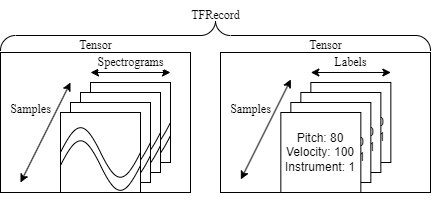

In [3]:
upperDirectory: str = r'E:\QUB\Stage3\CSC3002-Project\nsynth-data'
datasetName: str = 'GeneratedDataset'
datasets: list = glob(os.path.join(upperDirectory, '*', datasetName))

[print(dataset) for dataset in datasets];

E:\QUB\Stage3\CSC3002-Project\nsynth-data\nsynth-test\GeneratedDataset
E:\QUB\Stage3\CSC3002-Project\nsynth-data\nsynth-valid\GeneratedDataset
E:\QUB\Stage3\CSC3002-Project\nsynth-data\nsynth-train\GeneratedDataset


This cell defines the loop which is used to load each of the datasets. It makes calls to other functions to validate each dataset as they are loaded.

In [17]:
def loadDataset(path:str) -> (tf.data.Dataset, bool):
    """
    Loads a tf dataset from a filepath.
    :param path: The filepath for the tfrecord file.
    :return: A tuple where the first element is the loaded dataset.
    :return: The second element is a flag for is the function was successful.
    """
    try:
        with tf.device('/CPU:0'):
            dataset = tf.data.Dataset.load(path)
    except FileNotFoundError:
        return None, False
    return dataset, True

def verifyDatasets(datasets: list) -> bool:
    """
    Determines if all the datasets in a list have been loaded correctly.
    :param datasets: A list of loaded datasets.
    :return: A boolean value for if the datasets are all valid or not.
    """
    result = [isinstance(dataset, tf.data.Dataset) for dataset in datasets]
    if result == [True, True, True]:
        return True
    return False

def loadDatasets(paths: list) -> (list, bool):
    """
    Iterates through directories and loads them as tf datasets.
    :param paths: A list of directories.
    :return: A list of datasets and a validation flag.
    """
    datasets = [None, None, None]
    for path in paths:
        if 'train' in path:
            datasets[0], flag = loadDataset(path)
            if not flag:
                return [], False
        elif 'test' in path:
            datasets[1], flag = loadDataset(path)
            if not flag:
                return [], False
        elif 'valid' in path:
            datasets[2], flag = loadDataset(path)
            if not flag:
                return [], False
        else:
            pass
    if not verifyDatasets(datasets):
        return [], False
    return datasets, True

Here the above functions are called and the datasets are loaded into:<br><code>trainData, testData and validData</code> and will tell the user if it is successful or not.

In [18]:
data, validLoading = loadDatasets(datasets)
if validLoading:
    trainData, testData, validData = data
    print('Successfully loaded datasets')
else:
    print('Unable to load datasets')

Successfully loaded datasets


## Section 2: Visualise Test Data
To confirm the dataset contains usable data and to determine its size we will visualise one of the spectrograms. The size of this spectrogram is used later to define the input shape of the deep learning model.

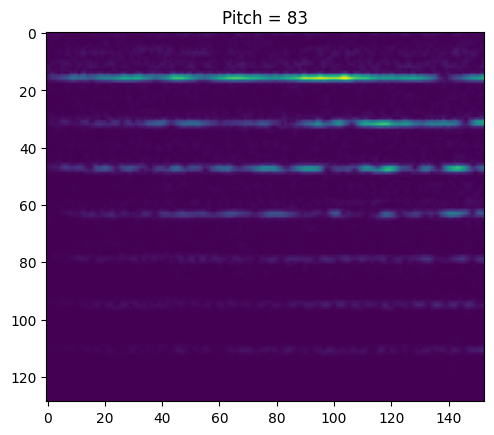

In [22]:
sample, label = trainData.take(1).as_numpy_iterator().next()
plt.figure()
plt.imshow(sample)
plt.title(f"Pitch = {label}")
plt.show()

## Section 3: Batch Dataset
The next cell will take the datasets we have loaded in memory and batch process them so that the model can train more efficiently. By re-batching the data it can be loaded into short term memory before it is fed into the model, drastically increasing training time. The prefetch method is also used to load even more of the data before so that it can perform even better.<br>
```Using larger batch sizes is only possible on more powerful hardware.```

In [23]:
batchSize = 128
prefetchSize = int(batchSize/2)

trainData = trainData.batch(batchSize).prefetch(prefetchSize)
validData = validData.batch(batchSize).prefetch(prefetchSize)

## Section 4: Define Model
This section is where the architecture of the deep learning model is defined. This code represents the 8<sup>th</sup> variation of the model.<br>You can see the convolutional layers that make up the model. There is also an advanced technique used here, <code>with stately.scope():</code>. This is using a distributed training strategy to spread the training evenly across all the GPUs evenly and uses the CPU for data management.

In [25]:
model_name = 'Model8'
tensorboard = TensorBoard(log_dir="logs/{}".format(model_name))

In [ ]:
with strategy.scope():
    model = Sequential()
    model.add(Input(shape=sample.shape))
    model.add(Dropout(0.2))
    model.add(Conv2D(64, (3,3), activation='relu'))
    model.add(MaxPooling2D(pool_size=(2,2)))
    model.add(Conv2D(128, (3,3), activation='relu'))
    model.add(MaxPooling2D(pool_size=(2,2)))
    model.add(Conv2D(128, (3,3), activation='relu'))
    model.add(MaxPooling2D(pool_size=(2,2)))
    model.add(Conv2D(256, (3,3), activation='relu'))
    model.add(MaxPooling2D(pool_size=(2,2)))
    model.add(Flatten())
    model.add(Dropout(0.5))
    model.add(Dense(512, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(128, activation='linear'))

## Section 5: Compile Model
After defining the model it is now ready to be trained. To accomplish this we must first compile the model and define the training parameters.

In [ ]:
with strategy.scope():
    optimizer = Adam(learning_rate=0.001)
    model.compile(
        loss='sparse_categorical_crossentropy',
        optimizer=optimizer,
        metrics=['accuracy']
    )

In [ ]:
model.summary()

## Section 6: Model Training
The model is now ready to be fit against the training dataset. During training the progress of the model can be viewed using tensorboard which can be accessed by running <code>tensorboard --logdir=logs/.</code> In a command prompt.

In [ ]:
model.fit(
    trainData,
    epochs=100,
    batch_size=128,
    validation_data=validData,
    callbacks=[tensorboard],
    verbose=0
)

The following are charts produced from Tensorboard data for `Model8` over the first 50 epochs.
![png](Loss%20Curve.png)
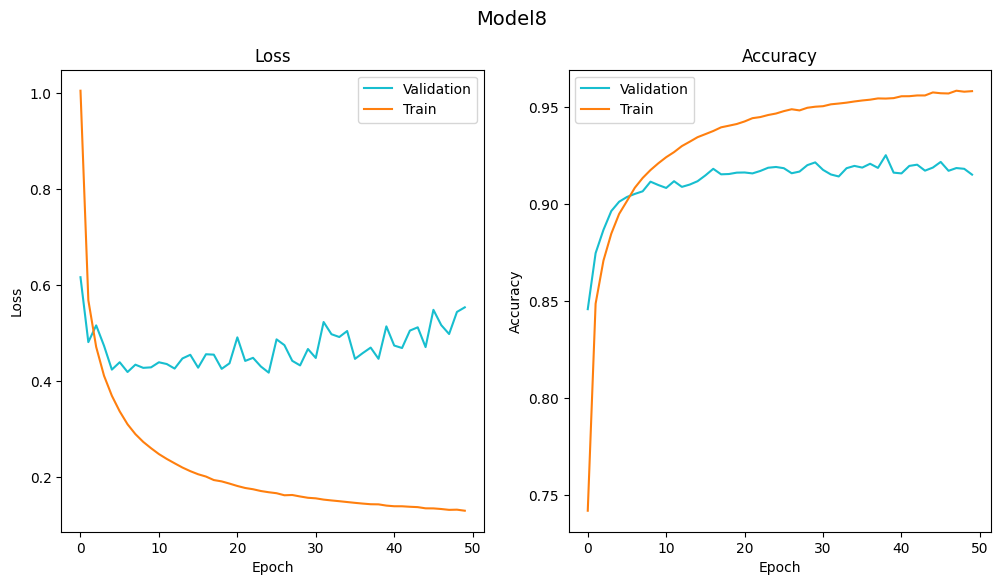

## Section 7: Model Validation and Export
After the model is trained its final accuracy can be calculated against the test dataset.

In [117]:
predictions = model.predict(testData.batch(128), verbose=0)
_, labels = list(zip(*testData))

accuracyTest = [labels[i].numpy() == np.argmax(p) for i, p in enumerate(predictions)]
acc = round((accuracyTest.count(True)/len(accuracyTest))*100, 2)
print(f'Total tests: {len(accuracyTest)}')
print(f'Accuracy: {acc}%')

Total tests: 4096
Accuracy: 91.31%


In [ ]:
model.save(model_name)